🚀 FULL BENCHMARK MODE: Running 600 PV & 300 PlantDoc episodes...
PlantVillage: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
PlantDoc:     /kaggle/input/datasets/tanvirakon/plantdoc-test-train-merged/combined
Checkpoint:   /kaggle/input/models/tanvirakon/main/pytorch/default/1/opus.pth
Checkpoint loaded strictly. Learned temperature: 0.2511

Generating deterministic benchmark episodes...

PlantVillage unseen-test inference:
  Completed 50/600 episodes
  Completed 100/600 episodes
  Completed 150/600 episodes
  Completed 200/600 episodes
  Completed 250/600 episodes
  Completed 300/600 episodes
  Completed 350/600 episodes
  Completed 400/600 episodes
  Completed 450/600 episodes
  Completed 500/600 episodes
  Completed 550/600 episodes
  Completed 600/600 episodes

PlantDoc unseen cross-domain inference:
  Completed 50/300 episodes
  Completed 100/300 episodes
  Completed 150/300 episodes
  Completed 200/300 episodes
  Completed 250/300 episodes
  Completed 300/300 e

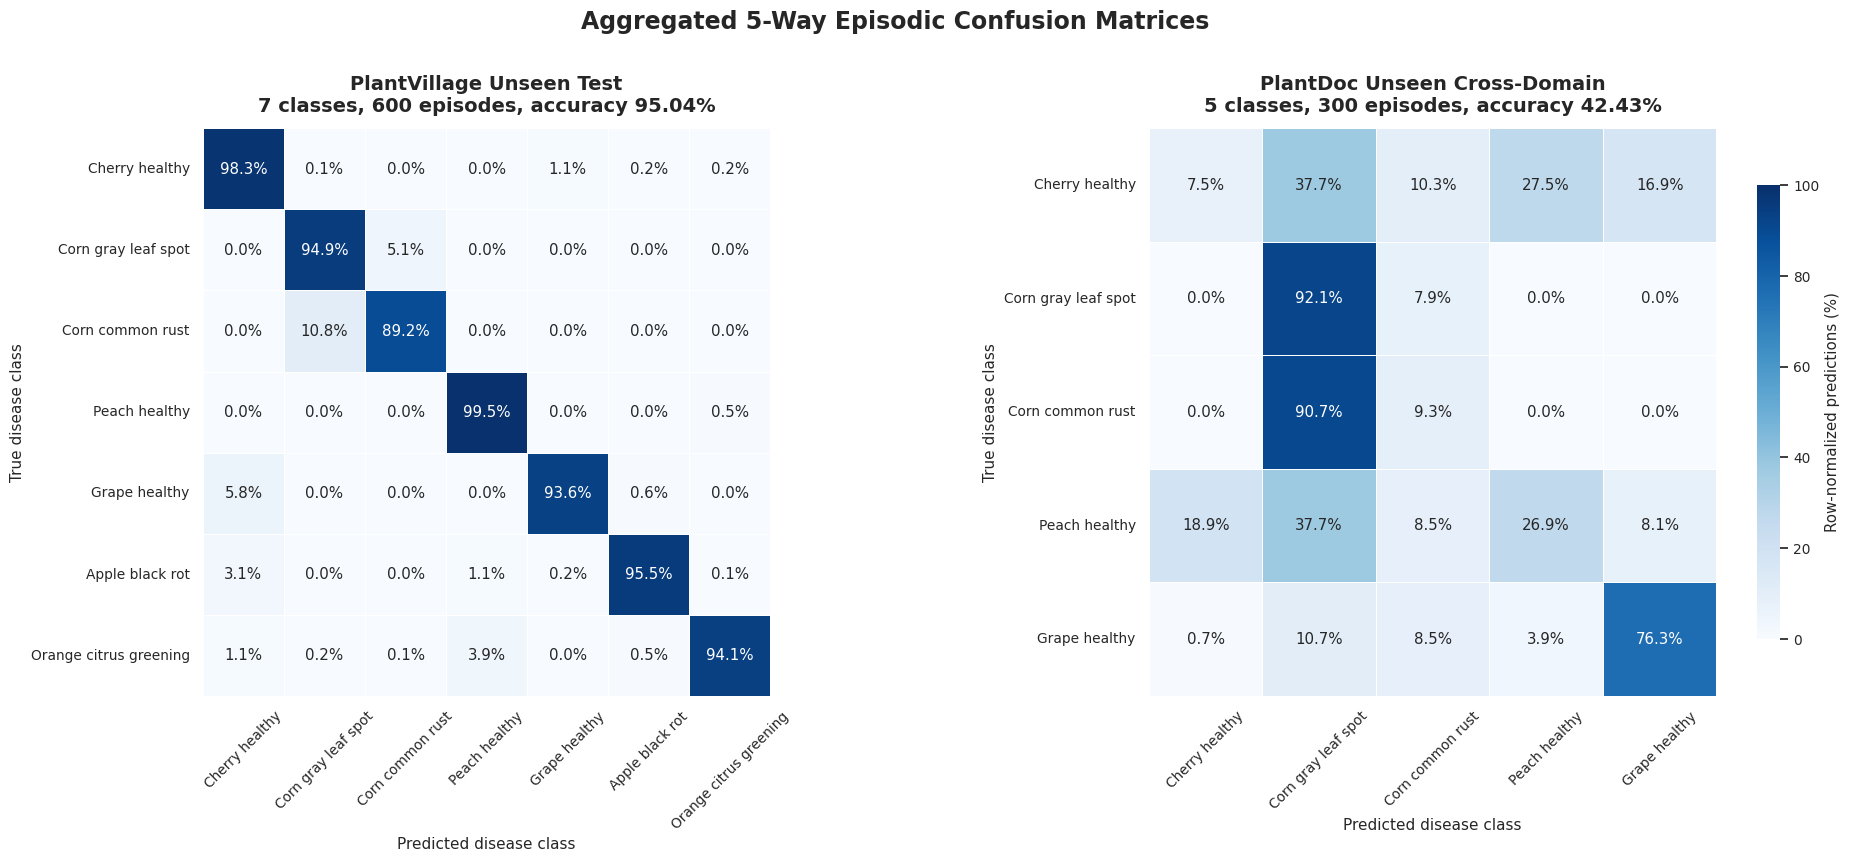

In [1]:
import csv
import os
import random
from collections import defaultdict
from contextlib import nullcontext

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix
from torchvision import datasets, models, transforms


# Kaggle inputs. The fallback search handles Kaggle's shortened mount paths.
PLANTVILLAGE_ROOT = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
PLANTDOC_ROOT = "/kaggle/input/datasets/tanvirakon/plantdoc-test-train-merged/combined"
WEIGHTS_PATH = "/kaggle/input/models/tanvirakon/main/pytorch/default/1/opus.pth"
OUTPUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMAGE_SIZE = 224
N_WAY = 5
K_SHOT = 5
SPLIT_SEED = 42

DRY_RUN = False  # Set to False when ready for full benchmark execution

# Benchmark protocols
if DRY_RUN:
    print("⚠️ DRY RUN MODE ACTIVE: Running 2 episodes for quick verification...")
    PV_QUERY = 2
    PV_EPISODES = 2
    PD_QUERY = 2
    PD_EPISODES = 2
else:
    print("🚀 FULL BENCHMARK MODE: Running 600 PV & 300 PlantDoc episodes...")
    PV_QUERY = 15
    PV_EPISODES = 600
    PD_QUERY = 5
    PD_EPISODES = 300

PV_EPISODE_SEED = SPLIT_SEED + 200002
PD_EPISODE_SEED = SPLIT_SEED + 400000


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def find_dataset_root(preferred, dataset_token, leaf_name):
    if os.path.isdir(preferred):
        return preferred

    candidates = []
    for search_root in ("/kaggle/input", "."):
        if not os.path.isdir(search_root):
            continue
        for root, _, _ in os.walk(search_root):
            if (
                os.path.basename(root).lower() == leaf_name.lower()
                and dataset_token in root.lower()
            ):
                candidates.append(root)

    if not candidates:
        raise FileNotFoundError(
            f"Could not find the {dataset_token} '{leaf_name}' directory. "
            "Attach the dataset to this Kaggle notebook."
        )
    return sorted(candidates)[0]


def find_weights():
    if os.path.isfile(WEIGHTS_PATH):
        return WEIGHTS_PATH

    candidates = []
    for search_root in ("/kaggle/input", "/kaggle/working", "."):
        if not os.path.isdir(search_root):
            continue
        for root, _, files in os.walk(search_root):
            candidates.extend(
                os.path.join(root, name)
                for name in files
                if name.lower().endswith((".pth", ".pt"))
            )

    candidates = sorted(set(candidates))
    if len(candidates) == 1:
        return candidates[0]
    if not candidates:
        raise FileNotFoundError("No .pth or .pt checkpoint was found.")
    raise RuntimeError(
        "Multiple checkpoints were found. Set WEIGHTS_PATH explicitly:\n  "
        + "\n  ".join(candidates)
    )


class ChannelAttention(nn.Module):
    def __init__(self, in_planes, reduction=16):
        super().__init__()
        reduced = max(1, in_planes // reduction)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, reduced, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(reduced, in_planes, 1, bias=False),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        mask = self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))
        return x * mask


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv1 = nn.Conv2d(
            2, 1, kernel_size, padding=kernel_size // 2, bias=False
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        mask = self.sigmoid(self.conv1(torch.cat([avg_out, max_out], dim=1)))
        return x * mask


class DualAttention(nn.Module):
    def __init__(self, in_planes, reduction=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, reduction)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        return self.sa(self.ca(x))


class EfficientNetB0FSL(nn.Module):
    def __init__(self):
        super().__init__()
        effnet = models.efficientnet_b0(weights=None)
        self.features_early = effnet.features[:7]
        self.attention_mid = DualAttention(192, reduction=8)
        self.features_late = effnet.features[7:]
        self.attention_final = DualAttention(1280, reduction=16)
        self.pooling = nn.AdaptiveAvgPool2d(1)
        self.mid_proj = nn.Linear(192, 128)
        self.late_proj = nn.Linear(1280, 128)
        self.mcd_dropout = nn.Dropout(p=0.5)
        self.proj = nn.Linear(256, 256)
        self.temperature = nn.Parameter(torch.tensor(1.0))

    def forward(self, x):
        x = self.features_early(x)
        x_mid = self.attention_mid(x)
        x_late = self.attention_final(self.features_late(x_mid))
        mid_feat = self.mid_proj(torch.flatten(self.pooling(x_mid), 1))
        late_feat = self.late_proj(torch.flatten(self.pooling(x_late), 1))
        combined = torch.cat([mid_feat, late_feat], dim=1)
        return F.normalize(self.proj(self.mcd_dropout(combined)), dim=1)


def load_checkpoint_strict(model, checkpoint_path):
    try:
        state = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    except TypeError:
        state = torch.load(checkpoint_path, map_location=DEVICE)

    if isinstance(state, nn.Module):
        state = state.state_dict()
    if isinstance(state, dict):
        for key in ("model_state_dict", "state_dict", "model"):
            if key in state and isinstance(state[key], dict):
                state = state[key]
                break
    if not isinstance(state, dict):
        raise TypeError("Checkpoint does not contain a model state dictionary.")

    clean_state = {
        key.removeprefix("module."): value for key, value in state.items()
    }
    model.load_state_dict(clean_state, strict=True)


def compute_prototypes(embeddings, labels):
    return torch.stack(
        [embeddings[labels == class_id].mean(dim=0) for class_id in range(N_WAY)]
    )


def build_class_to_indices(dataset):
    result = defaultdict(list)
    for index, target in enumerate(dataset.targets):
        result[target].append(index)
    return dict(result)


def generate_pv_episodes(test_classes, class_to_indices):
    rng = random.Random(PV_EPISODE_SEED)
    episodes = []
    for episode_id in range(PV_EPISODES):
        sampled_classes = rng.sample(test_classes, N_WAY)
        support_indices, support_labels = [], []
        query_indices, query_labels = [], []

        for local_label, class_id in enumerate(sampled_classes):
            selected = rng.sample(
                class_to_indices[class_id], K_SHOT + PV_QUERY
            )
            support_indices.extend(selected[:K_SHOT])
            support_labels.extend([local_label] * K_SHOT)
            query_indices.extend(selected[K_SHOT:])
            query_labels.extend([local_label] * PV_QUERY)

        episodes.append(
            {
                "episode_id": episode_id,
                "classes": sampled_classes,
                "support_indices": support_indices,
                "support_labels": support_labels,
                "query_indices": query_indices,
                "query_labels": query_labels,
            }
        )
    return episodes


def generate_pd_episodes(unseen_pairs, pv_class_to_indices, pd_class_to_indices):
    rng = random.Random(PD_EPISODE_SEED)
    episodes = []
    for episode_id in range(PD_EPISODES):
        sampled_pairs = rng.sample(unseen_pairs, N_WAY)
        support_indices, support_labels = [], []
        query_indices, query_labels = [], []

        for local_label, (_, pv_id, pd_id) in enumerate(sampled_pairs):
            support_indices.extend(rng.sample(pv_class_to_indices[pv_id], K_SHOT))
            support_labels.extend([local_label] * K_SHOT)
            query_indices.extend(rng.sample(pd_class_to_indices[pd_id], PD_QUERY))
            query_labels.extend([local_label] * PD_QUERY)

        episodes.append(
            {
                "episode_id": episode_id,
                "pairs": sampled_pairs,
                "support_indices": support_indices,
                "support_labels": support_labels,
                "query_indices": query_indices,
                "query_labels": query_labels,
            }
        )
    return episodes


def autocast_context():
    if DEVICE == "cuda":
        return torch.amp.autocast("cuda")
    return nullcontext()


@torch.no_grad()
def evaluate_episodes(
    model, support_dataset, query_dataset, episodes, class_key, protocol_name
):
    true_names, predicted_names, rows = [], [], []
    model.eval()

    for episode_number, episode in enumerate(episodes, start=1):
        support_x = torch.stack(
            [support_dataset[index][0] for index in episode["support_indices"]]
        ).to(DEVICE)
        query_x = torch.stack(
            [query_dataset[index][0] for index in episode["query_indices"]]
        ).to(DEVICE)
        support_y = torch.tensor(
            episode["support_labels"], dtype=torch.long, device=DEVICE
        )

        with autocast_context():
            support_count = support_x.size(0)
            embeddings = model(torch.cat([support_x, query_x], dim=0))
            prototypes = compute_prototypes(embeddings[:support_count], support_y)
            logits = -torch.cdist(embeddings[support_count:], prototypes, p=2)
            logits = logits / model.temperature

        predicted_local = logits.argmax(dim=1).cpu().tolist()
        if class_key == "classes":
            episode_names = [support_dataset.classes[i] for i in episode[class_key]]
        else:
            episode_names = [pair[0] for pair in episode[class_key]]

        for local_true, local_pred in zip(episode["query_labels"], predicted_local):
            true_name = episode_names[local_true]
            predicted_name = episode_names[local_pred]
            true_names.append(true_name)
            predicted_names.append(predicted_name)
            rows.append(
                (protocol_name, episode["episode_id"], true_name, predicted_name)
            )

        if episode_number % 50 == 0 or episode_number == len(episodes):
            print(f"  Completed {episode_number}/{len(episodes)} episodes")

    return true_names, predicted_names, rows


def normalize_confusion(true_names, predicted_names, labels):
    matrix = confusion_matrix(true_names, predicted_names, labels=labels)
    row_totals = matrix.sum(axis=1, keepdims=True)
    return np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix, dtype=float),
        where=row_totals != 0,
    )


def percent_annotations(matrix):
    return np.array(
        [[f"{value * 100:.1f}%" for value in row] for row in matrix],
        dtype=object,
    )


def save_predictions(rows):
    path = os.path.join(OUTPUT_DIR, "benchmark_confusion_predictions.csv")
    with open(path, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["protocol", "episode_id", "true_class", "predicted_class"])
        writer.writerows(rows)
    print(f"Saved predictions: {path}")


set_seed(SPLIT_SEED)
PLANTVILLAGE_ROOT = find_dataset_root(
    PLANTVILLAGE_ROOT, "plantvillage", "color"
)
PLANTDOC_ROOT = find_dataset_root(PLANTDOC_ROOT, "plantdoc", "combined")

test_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

print(f"PlantVillage: {PLANTVILLAGE_ROOT}")
print(f"PlantDoc:     {PLANTDOC_ROOT}")
pv_dataset = datasets.ImageFolder(PLANTVILLAGE_ROOT, transform=test_transform)
pd_dataset = datasets.ImageFolder(PLANTDOC_ROOT, transform=test_transform)
pv_class_to_indices = build_class_to_indices(pv_dataset)
pd_class_to_indices = build_class_to_indices(pd_dataset)
pv_name_to_id = {name: index for index, name in enumerate(pv_dataset.classes)}
pd_name_to_id = {name: index for index, name in enumerate(pd_dataset.classes)}

if len(pv_dataset.classes) != 38:
    raise ValueError(
        f"Expected 38 PlantVillage classes, found {len(pv_dataset.classes)}."
    )

all_pv_classes = list(range(len(pv_dataset.classes)))
random.Random(SPLIT_SEED).shuffle(all_pv_classes)
pv_test_classes = all_pv_classes[31:38]

PD_TO_PV_MAPPING = {
    "Cherry_leaf": "Cherry_(including_sour)___healthy",
    "Corn_Gray_leaf_spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_rust_leaf": "Corn_(maize)___Common_rust_",
    "grape_leaf": "Grape___healthy",
    "Peach_leaf": "Peach___healthy",
}

unseen_pairs = sorted(
    [
        (pd_name, pv_name_to_id[pv_name], pd_name_to_id[pd_name])
        for pd_name, pv_name in PD_TO_PV_MAPPING.items()
        if pv_name_to_id[pv_name] in set(pv_test_classes)
    ],
    key=lambda pair: pair[0],
)
if len(unseen_pairs) != N_WAY:
    raise ValueError(
        f"Expected exactly {N_WAY} mapped PlantDoc unseen classes, "
        f"found {len(unseen_pairs)}."
    )

checkpoint_path = find_weights()
print(f"Checkpoint:   {checkpoint_path}")
model = EfficientNetB0FSL().to(DEVICE)
load_checkpoint_strict(model, checkpoint_path)
model.eval()
print(
    f"Checkpoint loaded strictly. Learned temperature: "
    f"{model.temperature.item():.4f}"
)

print("\nGenerating deterministic benchmark episodes...")
pv_fixed_episodes = generate_pv_episodes(pv_test_classes, pv_class_to_indices)
pd_fixed_episodes = generate_pd_episodes(
    unseen_pairs, pv_class_to_indices, pd_class_to_indices
)

print("\nPlantVillage unseen-test inference:")
pv_true, pv_predicted, pv_rows = evaluate_episodes(
    model,
    pv_dataset,
    pv_dataset,
    pv_fixed_episodes,
    class_key="classes",
    protocol_name="plantvillage_unseen",
)

print("\nPlantDoc unseen cross-domain inference:")
pd_true, pd_predicted, pd_rows = evaluate_episodes(
    model,
    pv_dataset,
    pd_dataset,
    pd_fixed_episodes,
    class_key="pairs",
    protocol_name="plantdoc_unseen",
)
save_predictions(pv_rows + pd_rows)

pd_labels = [pair[0] for pair in unseen_pairs]
shared_pv_labels = [PD_TO_PV_MAPPING[name] for name in pd_labels]
pv_test_names = [pv_dataset.classes[index] for index in pv_test_classes]
pv_labels = shared_pv_labels + sorted(set(pv_test_names) - set(shared_pv_labels))
pv_matrix = normalize_confusion(pv_true, pv_predicted, pv_labels)
pd_matrix = normalize_confusion(pd_true, pd_predicted, pd_labels)

pv_accuracy = np.mean(np.asarray(pv_true) == np.asarray(pv_predicted)) * 100
pd_accuracy = np.mean(np.asarray(pd_true) == np.asarray(pd_predicted)) * 100
print(f"PlantVillage deterministic accuracy: {pv_accuracy:.2f}%")
print(f"PlantDoc deterministic accuracy:     {pd_accuracy:.2f}%")

display_names = {
    "Apple___Black_rot": "Apple black rot",
    "Cherry_(including_sour)___healthy": "Cherry healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": "Corn gray leaf spot",
    "Corn_(maize)___Common_rust_": "Corn common rust",
    "Grape___healthy": "Grape healthy",
    "Orange___Haunglongbing_(Citrus_greening)": "Orange citrus greening",
    "Peach___healthy": "Peach healthy",
    "Cherry_leaf": "Cherry healthy",
    "Corn_Gray_leaf_spot": "Corn gray leaf spot",
    "Corn_rust_leaf": "Corn common rust",
    "grape_leaf": "Grape healthy",
    "Peach_leaf": "Peach healthy",
}

sns.set_theme(style="white", font_scale=0.9)
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))

sns.heatmap(
    pv_matrix * 100,
    annot=percent_annotations(pv_matrix),
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    square=True,
    cbar=False,
    linewidths=0.5,
    xticklabels=[display_names[name] for name in pv_labels],
    yticklabels=[display_names[name] for name in pv_labels],
    ax=axes[0],
)
axes[0].set_title(
    f"PlantVillage Unseen Test\n7 classes, 600 episodes, accuracy {pv_accuracy:.2f}%",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

sns.heatmap(
    pd_matrix * 100,
    annot=percent_annotations(pd_matrix),
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=100,
    square=True,
    cbar=True,
    cbar_kws={"label": "Row-normalized predictions (%)", "shrink": 0.8},
    linewidths=0.5,
    xticklabels=[display_names[name] for name in pd_labels],
    yticklabels=[display_names[name] for name in pd_labels],
    ax=axes[1],
)
axes[1].set_title(
    f"PlantDoc Unseen Cross-Domain\n5 classes, 300 episodes, accuracy {pd_accuracy:.2f}%",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

for axis in axes:
    axis.set_xlabel("Predicted disease class", fontsize=11)
    axis.set_ylabel("True disease class", fontsize=11)
    axis.tick_params(axis="x", rotation=45)
    axis.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Aggregated 5-Way Episodic Confusion Matrices",
    fontsize=17,
    fontweight="bold",
    y=1.01,
)
fig.tight_layout()

png_path = os.path.join(OUTPUT_DIR, "benchmark_unseen_confusion_matrices.png")
pdf_path = os.path.join(OUTPUT_DIR, "benchmark_unseen_confusion_matrices.pdf")
fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
print(f"Saved figure: {png_path}")
print(f"Saved figure: {pdf_path}")
plt.show()
